<a href="https://colab.research.google.com/github/weronikajopek/ml4space/blob/main/Basic_opt.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Basic Optimization

In this page we shall demosntrate how to use Scipy's optimization package.


Lets optimize $f(x) = \exp{(x-2)^2}$

In [1]:
!pip install scikit-optimize

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [scikit-optimize]


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import numpy as np
import matplotlib.pyplot as mp
import scipy as sp
from scipy import optimize
from scipy import fftpack
import skopt as opt

def f(y):
    return -np.exp(-(y-2)**2)

result = optimize.minimize_scalar(f)

print(result)

 message: 
          Optimization terminated successfully;
          The returned value satisfies the termination criteria
          (using xtol = 1.48e-08 )
 success: True
     fun: -1.0
       x: 1.9999999955459995
     nit: 6
    nfev: 10



###Using minimize function
We can also use Python's minimize or maximize function (with the ''key'' option) to optimize the function!

You can also pass more arguments.

Why to use the "optimize" function then?

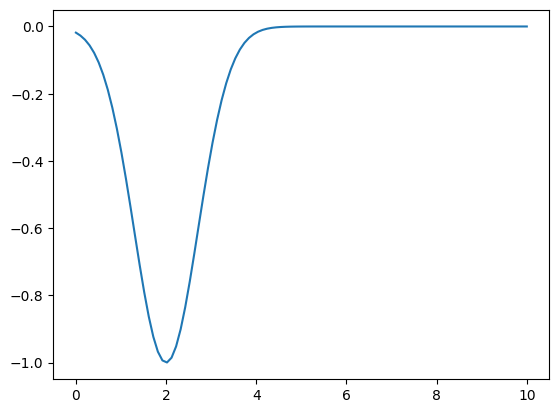

2.0202020202020203


In [4]:
y = np.linspace(0,10,100)
mp.plot(y,-np.exp(-(y-2)**2)); mp.show()
#print(max(y, key=lambda x: np.sinc(x-5)))

print(min(y, key=lambda x: -np.exp(-(x-2)**2)))

###Rosenbrock function

Now we optimize the infamous Rosenbrock function.

$f(x,y) = 0.5*(1-x)^2 + (y - x^2)^2$

In [5]:
def f(x):   # The rosenbrock function
    return .5*(1 - x[0])**2 + (x[1] - x[0]**2)**2
optimize.minimize(f, [0,-1], method="CG")

 message: Optimization terminated successfully.
 success: True
  status: 0
     fun: 1.2743806081839638e-11
       x: [ 1.000e+00  1.000e+00]
     nit: 8
     jac: [-2.100e-07  2.518e-06]
    nfev: 48
    njev: 16

What happens if we change the seed to something very far from the solution point?

In [6]:
optimize.minimize(f, [200,-110], method="CG")

 message: Optimization terminated successfully.
 success: True
  status: 0
     fun: 2.988484547652788e-10
       x: [ 1.000e+00  1.000e+00]
     nit: 19
     jac: [ 6.786e-06  8.505e-06]
    nfev: 158
    njev: 52

**Constrained Optimization**

In this you need to give the constraints as well.

For example: $f(x) = 2xy + 2x - x^2 - 2 y^2$.

Constraints are as follows:

$x^3−y = 0$

$y−1 \geq 0$

In [7]:
def func(x, sign=1.0):
    """ Objective function """
    return sign*(2*x[0]*x[1] + 2*x[0] - x[0]**2 - 2*x[1]**2)

cons = ({'type': 'eq',
          'fun' : lambda x: np.array([x[0]**3 - x[1]])},
        {'type': 'ineq',
          'fun' : lambda x: np.array([x[1] - 1])})

res = optimize.minimize(func, [-1.0,1.0], args=(-1.0,),
                method='SLSQP', options={'disp': True})
print(res.x)

Optimization terminated successfully    (Exit mode 0)
            Current function value: -1.999999999999997
            Iterations: 4
            Function evaluations: 13
            Gradient evaluations: 4
[1.99999994 0.99999995]


In [8]:
res = optimize.minimize(func, [-1.0,1.0], args=(-1.0,),
                constraints=cons, method='BFGS', options={'disp': True})

print(res.x)

Optimization terminated successfully.
         Current function value: -2.000000
         Iterations: 6
         Function evaluations: 21
         Gradient evaluations: 7
[2.00000009 1.00000005]


/tmp/ipykernel_10185/2128810766.py:1: RuntimeWarning: Method BFGS cannot handle constraints.
  res = optimize.minimize(func, [-1.0,1.0], args=(-1.0,),


## COMPRESSIVE SENSING

Now lets discuss about compressive sensing. Lets assume that we have some signal recorded (following Nyquist rate); lets call it $x$. Its size is $N$.

In the following signal we are using 500 samples and two sinusoids. You can note that one of them takes 10 samples per cycle; hence there are 50 cycles. So Nyquist will want us to have at least 100 samples in order to be able to know whats in the signal!

However if we look the signal through DCT then there are just two samples. Mark that we are using DCT and not FFT; because then we dont have to deal with complex numbers!



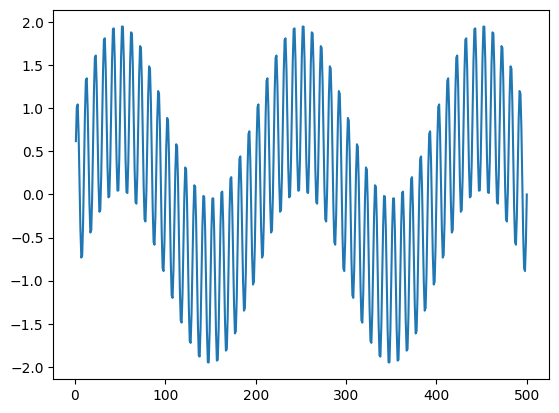

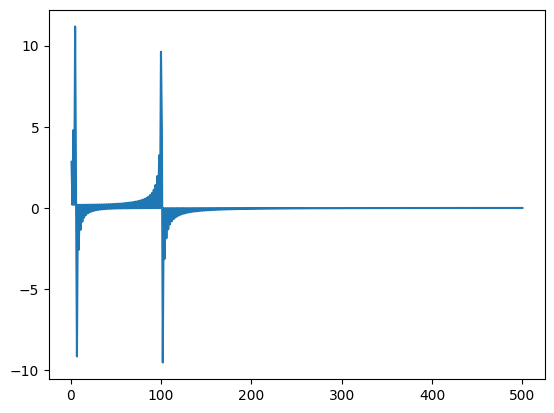

([<matplotlib.lines.Line2D at 0x7b74a971d590>], None)

In [9]:
n = np.linspace(1,500,500)

#two harmonics signal
xx = np.sin(2*np.pi*n/10) + np.sin(2*np.pi*n/200)  #+ np.sin(2*np.pi*n/50)
mp.plot(n,xx), mp.show()
mp.plot(n,fftpack.dct(xx, norm='ortho')), mp.show()

**Sparse Sampling** \\
Lets assume that we only consider $n$ of this ($n \ll N$).

For this lets define a sparsifying vector sp which has only $n$ 1's and rest zeros placed in random places.

So sparsed data $xp = xx*sp$.

The trick is that these $n$ samples are randomly taken.

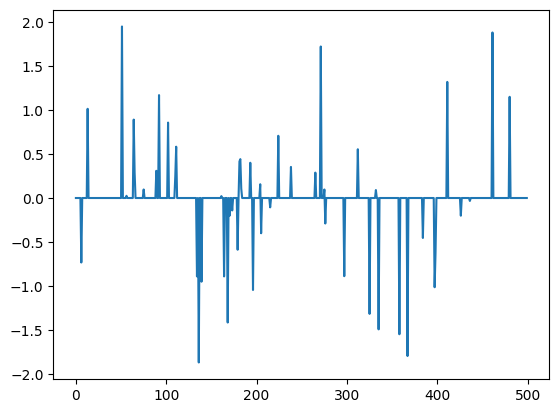

([<matplotlib.lines.Line2D at 0x7b74a5d6aad0>], None)

In [10]:
N = len(xx) #length of actual N
n = 50 #number of nonzero samples in our sparse signal
sp = np.array([1] * n + [0] * (N-n)) #n 1's and (N-n) 0's
np.random.shuffle(sp)

xp = xx*sp
mp.plot(xp), mp.show()

### Using Optimization
The trick of compressive sensing is that we try to use optimization in order to know the unknown from what is known!

So let us think what we know.

1- We know $xp$  the random-subNyquist-sampled signal and $sp$.

2- We know that the signal is sparse in DCT domain.

So lets try to look into the DCT domain. Lets assume that the DCT of the signal is $XX$. So IDCT of it should give us $xp$ back.

Lets define an optimization problem to do this.

What are the DCT samples that will give rise to a time domain signal which has the values of $xp$ at $sp$ time-indices. \\
We start with an intial estimate $XX$ which we will update in each iteration. \\
The cost function will be Euclidean distance between $xp$ and IDCT of $XX$.

/usr/local/lib/python3.13/dist-packages/scipy/optimize/_minimize.py:779: OptimizeWarning: Desired error not necessarily achieved due to precision loss.
  res = _minimize_bfgs(fun, x0, args, jac, callback, **options)


         Current function value: 0.000000
         Iterations: 3
         Function evaluations: 25062
         Gradient evaluations: 50


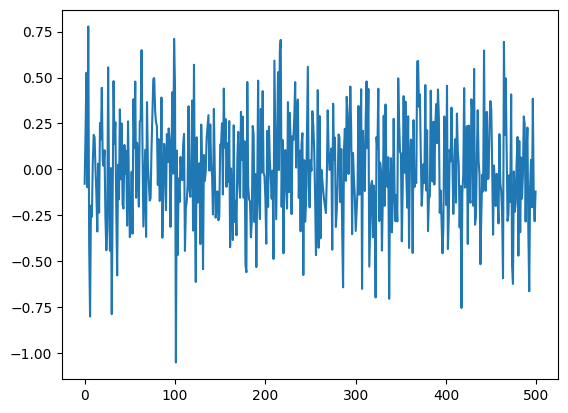

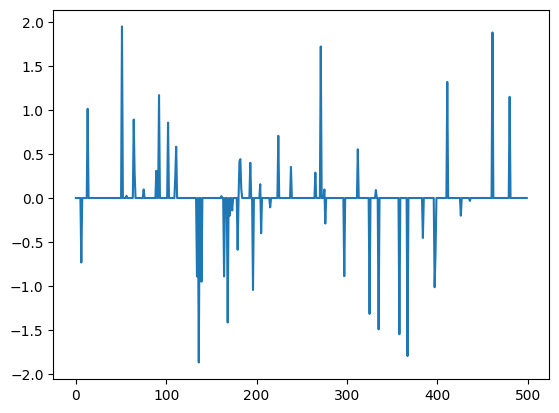

([<matplotlib.lines.Line2D at 0x7b74a96f4e10>], None)

In [11]:

XX = np.random.rand(N)
def cost_cs(XX):   #given the measured xp and a generic X find the L1 norm
    xd = fftpack.idct(XX, norm='ortho') #derived x from X
    xdn = xd*sp
    return np.linalg.norm((xdn - xp), ord=2)

seed = np.zeros(N)

CS = optimize.minimize(cost_cs, seed, options={'disp': True})

xrecon = fftpack.idct(CS.x, norm='ortho')
mp.plot(CS.x), mp.show()
mp.plot(xrecon), mp.show()

### Redfining the Optimization
Hmmmm. Enen though the optimization has not finished doing its job if we look at the result we seem to have achieved what we asked for!

The reconstructed signal $xrecon$ looks exactly like $xp$. So we did achieve what we wanted (theoritically speaking) but we want more.

What else can we do?

Lets add a condition that we want to optimize $||xrecon - xp ||$ but we also want to keep XX sparse, i.e. the $L0$ norm of $XX$ should be less than $n$.

Iteration limit reached    (Exit mode 9)
            Current function value: 1.3757937767461512e-05
            Iterations: 100
            Function evaluations: 51356
            Gradient evaluations: 101


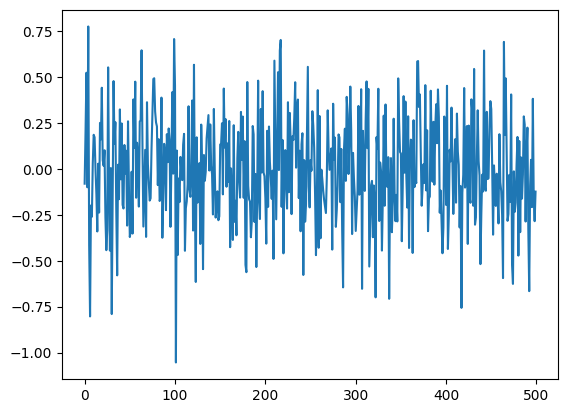

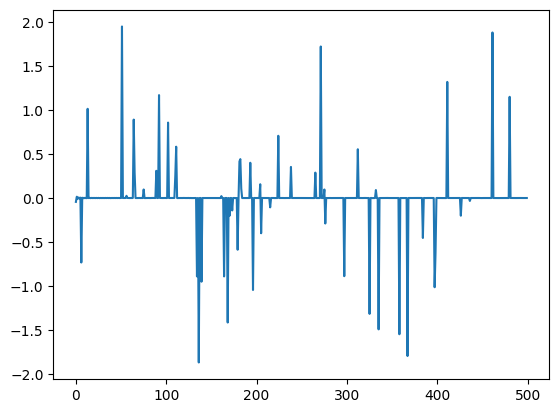

([<matplotlib.lines.Line2D at 0x7b74a5c6f890>], None)

In [12]:
XX = np.random.rand(N)
def cost_cs(XX):   #given the measured xp and a generic X find the L1 norm
    xd = fftpack.idct(XX, norm='ortho') #derived x from X
    xdn = xd*sp
    return np.linalg.norm((xdn - xp), ord=2)

cons = ({'type': 'ineq',
          'fun' : lambda XX: n - np.linalg.norm(XX,ord=0)})

#seed = np.random.rand(N)
seed = np.zeros(N)

CS = optimize.minimize(cost_cs, seed, constraints=cons, options={'disp': True})

xrecon = fftpack.idct(CS.x, norm='ortho')
mp.plot(CS.x), mp.show()
mp.plot(xrecon), mp.show()

### Re-redfining the Optimization: L1 Magic!!
Hmmmm. It seems its not working the way we want it to work. What else can we do?

It seems achieving $xrecon = xp$ is an easy task, because its sparse anyway.

So lets keep this as a condition (instead of making it the cost-function). And minimize $XX$. And let us use $L1$ norm here so as to keep the error under control. Remember that even though $L2$ norm is smooth, it has a square and blows up the error. So in wildly uknown problems like what we dealing with here, its better to use $L1$ norm.

In [13]:
XX = np.random.rand(N)
def cost_cs(XX):   #given the measured xp and a generic X find the L1 norm
    return np.linalg.norm(XX, ord=1)

cons = ({'type': 'eq',
          'fun' : lambda XX : np.linalg.norm(xp - fftpack.idct(XX, norm='ortho')*sp, ord = 2)})

seed = np.random.rand(N)
#seed = np.zeros(N)

CS = optimize.minimize(cost_cs, seed, constraints=cons, options={'disp': True})

Iteration limit reached    (Exit mode 9)
            Current function value: 59.714176037443025
            Iterations: 100
            Function evaluations: 50918
            Gradient evaluations: 101


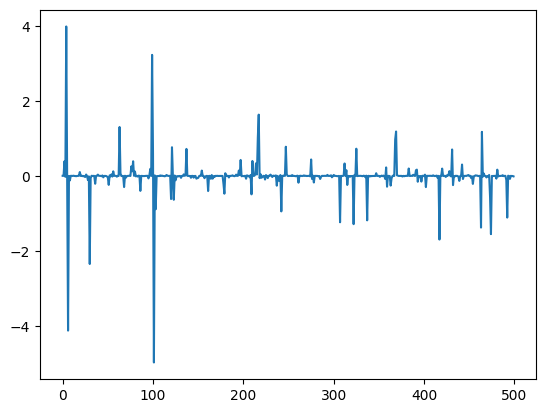

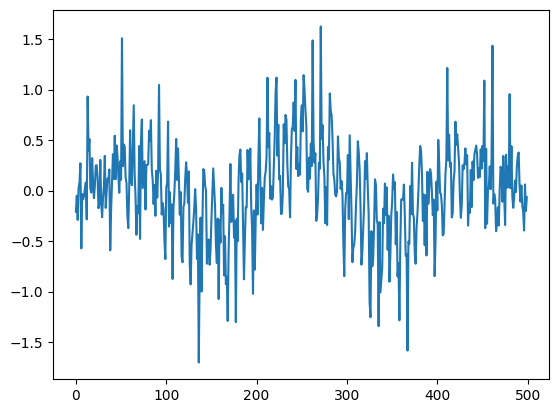

([<matplotlib.lines.Line2D at 0x7b74a5b88410>], None)

In [14]:
xrecon = fftpack.idct(CS.x, norm='ortho')
mp.plot(CS.x), mp.show()
mp.plot(xrecon), mp.show()

### Conclusion
Unfortunately the optimization process did not end. We need more iteration. However, we seem to have got something which looks pretty much like the signal we have started with. It is noisy but it is encouraging given the fact that we have got only half the number of samples as Nyquist would have wanted.

This is the starting of Compressive Sensing (CS). We have learnt two things.

1- It is easy to cheat Nyquist if the signal is sparse in some other linearly transferable domain. 2- Redefining the optimization problem can help us achieve magical results.

The hard-core CS involvs more interesting objective functions and constraints to achieve even more interesting magical results.

# EO

**EXERCISES TO DO:**

Part 1 - Probability Distribution Function (PDF) of Sentinel data

1. Access at least three bands of data of Sentinel 2 of natural and urban areas

2. Draw the histogram of the images

3. Note your observations

4. Repeat it for data from Sentinel-1 from the same regions

Part 2 - Stegenography

1. Take any of the images you have worked on for the last question. Replace the last two LSB (least significant bit)  of each pixel with a randomly generated number (random for each pixel).

2. Check if it affects the visual quality of the image

3. Plot the PDF (by plotting the histogram) of the original and manipulated images. Do you see any difference? Can this be used to detect if a satellite image has been manipulated?

4. (Optional) Run the compressive sensing code and note where it may be useful in EO


## PDF of Sentinel data

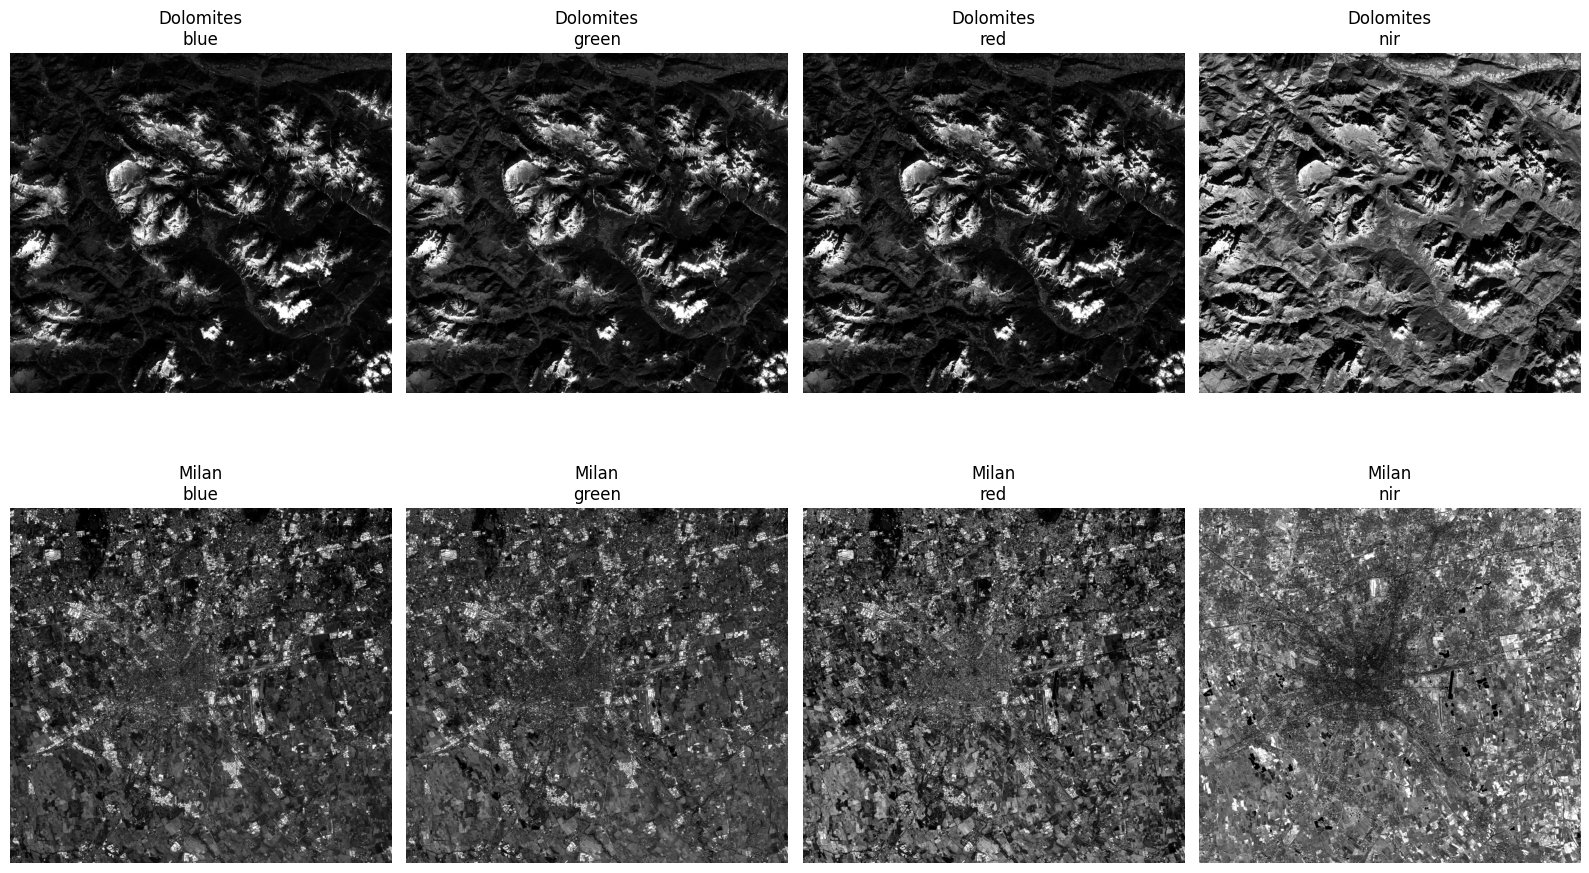

In [15]:
from pathlib import Path
import rasterio
import numpy as np
import matplotlib.pyplot as plt

IMAGE_DIR = Path('/content/drive/MyDrive/downstream/machine-learning/PDF/data')

def load_image(sensor, area, band):
    path = IMAGE_DIR / sensor / area / f"{band}.tiff"
    with rasterio.open(path) as src:
        image = src.read(1, masked=True)
    return image

bands = ["blue", "green", "red", "nir"]
areas = ["Dolomites", "Milan"]

fig, axes = plt.subplots(len(areas), len(bands), figsize=(16, 10))

for row, area in enumerate(areas):
    for col, band in enumerate(bands):
        image = load_image("Sentinel-2", area, band)

        vmin, vmax = np.percentile(image.compressed(), [2, 98])

        axes[row, col].imshow(image, cmap="gray", vmin=vmin, vmax=vmax)
        axes[row, col].set_title(f"{area}\n{band}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

**Observations:**
RGB bands pictures are very similar to each other. Natural areas - mountains and urban areas can be distinguished by contrast and texture, and NIR band separates land-cover types best.

Sentinel-1

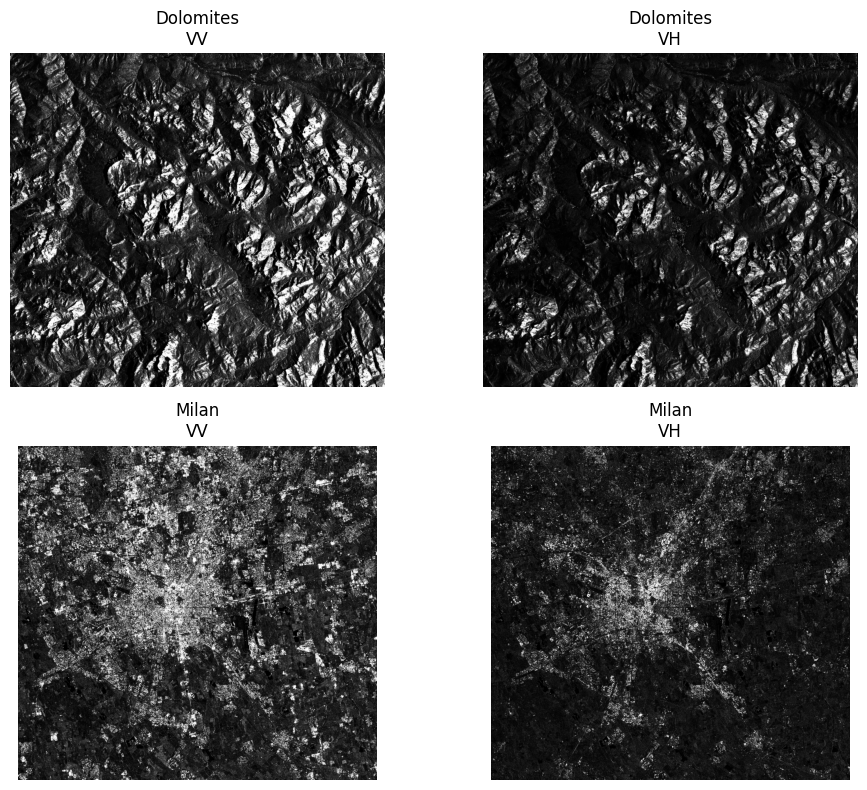

In [16]:
s1_bands = ["vv", "vh"]
areas = ["Dolomites", "Milan"]

fig, axes = plt.subplots(len(areas), len(s1_bands), figsize=(10, 8))

for row, area in enumerate(areas):
    for col, band in enumerate(s1_bands):
        image = load_image("Sentinel-1", area, band)

        vmin, vmax = np.percentile(image.compressed(), [2, 98])

        axes[row, col].imshow(image, cmap="gray", vmin=vmin, vmax=vmax)
        axes[row, col].set_title(f"{area}\n{band.upper()}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

## Histograms

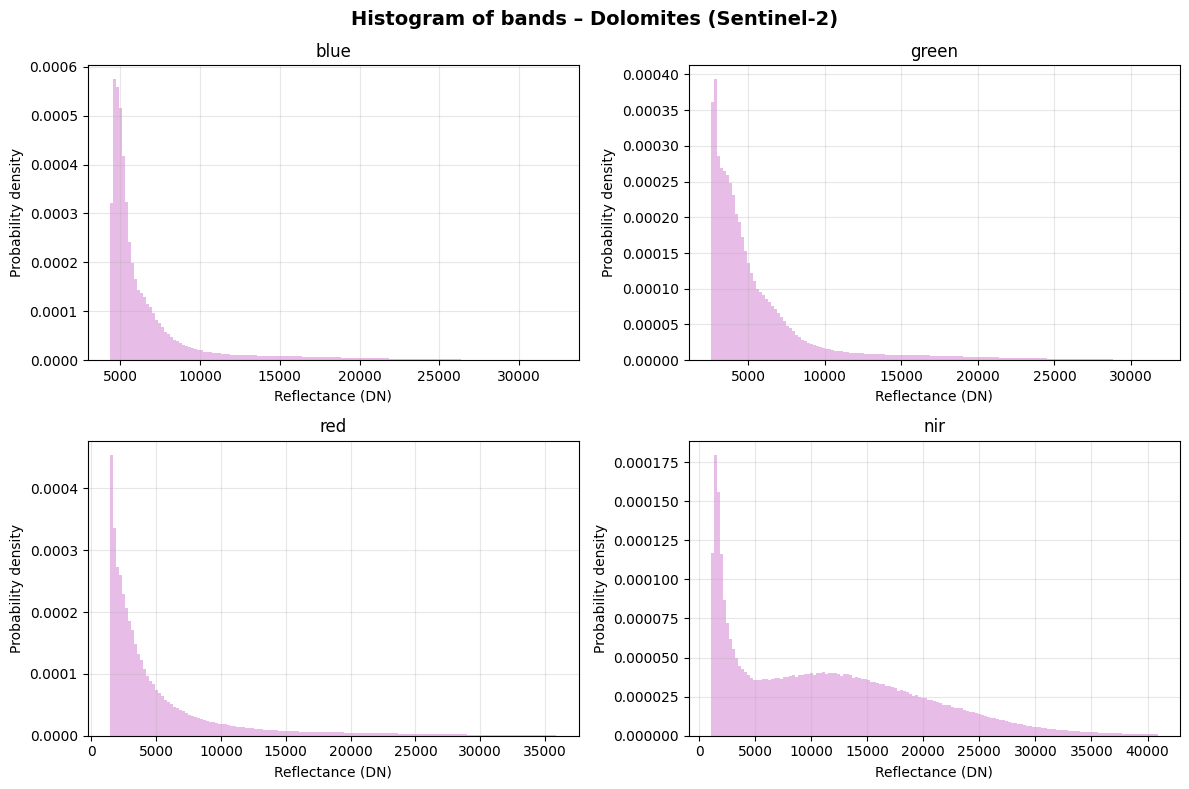

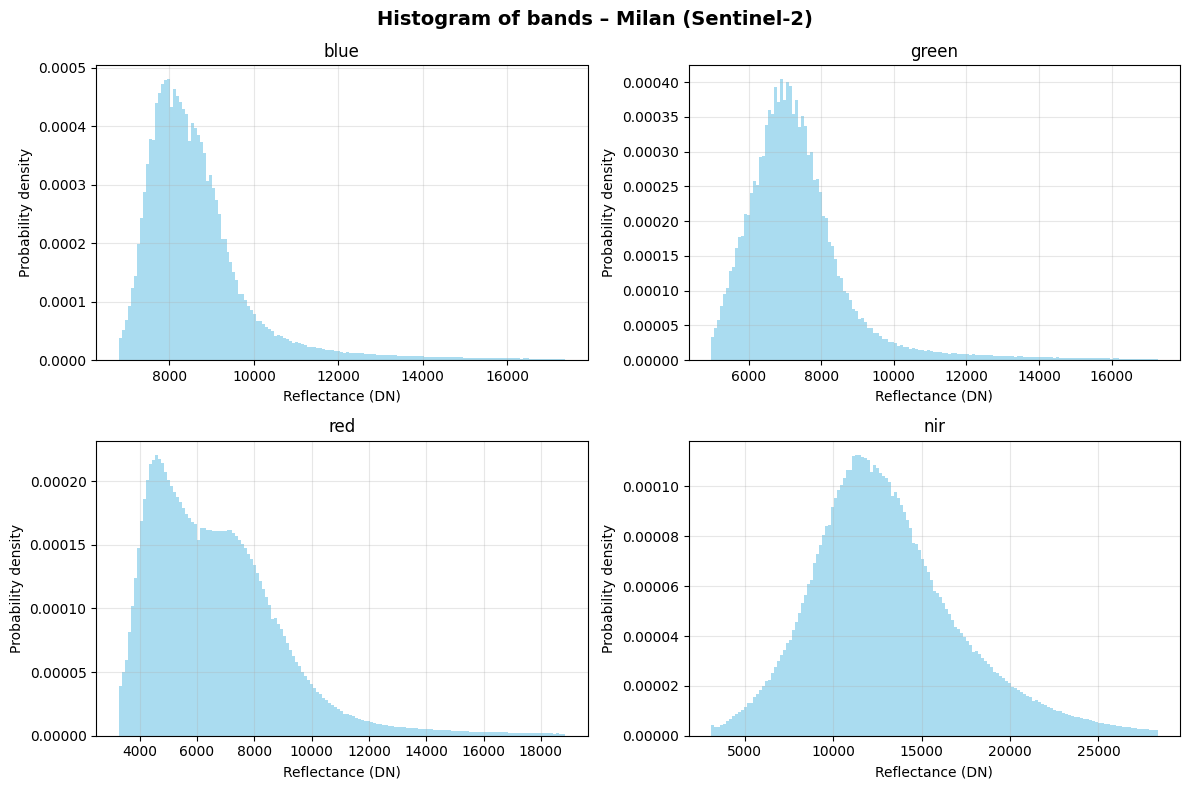

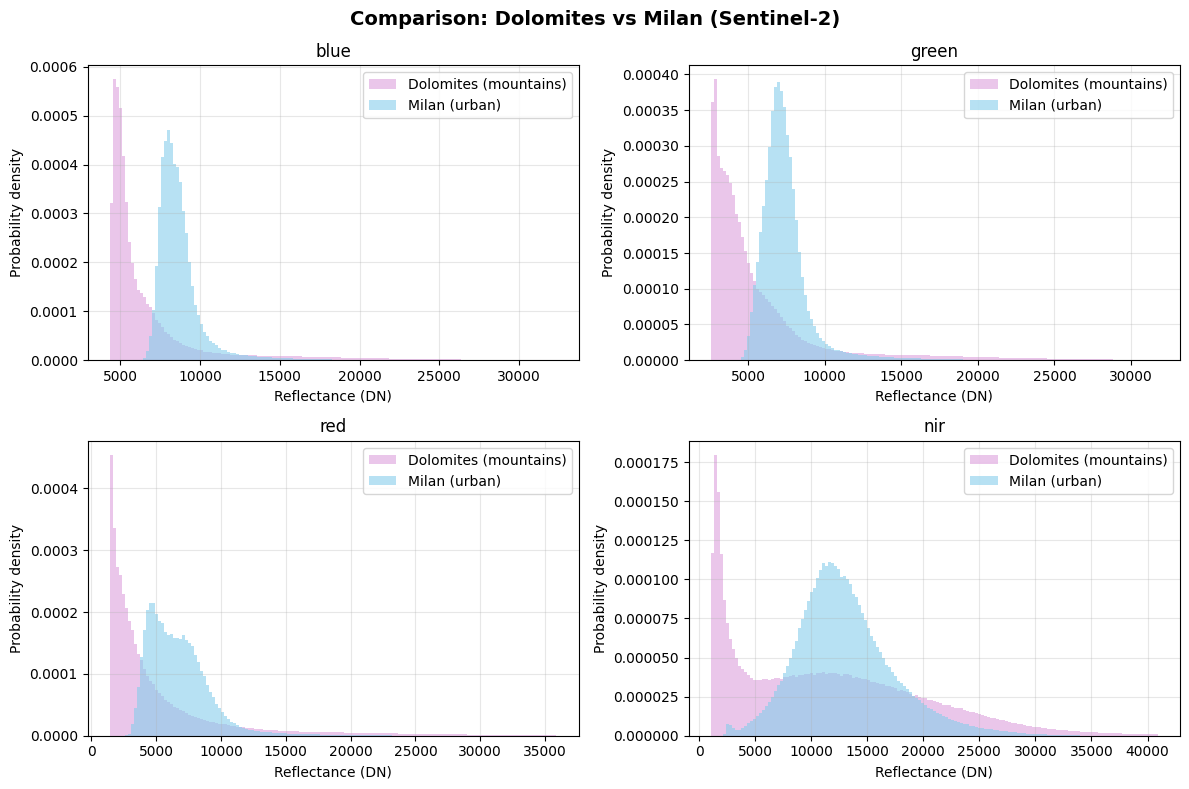

In [47]:
# Dolomites
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle("Histogram of bands – Dolomites (Sentinel-2)",
             fontsize=14,
             fontweight="bold")

for ax, band in zip(axes.flat, bands):
    data = load_image("Sentinel-2", "Dolomites", band).compressed().astype(np.float64)

    vmin, vmax = np.percentile(data, [0.5, 99.5])
    bins = np.linspace(float(vmin), float(vmax), 150)

    ax.hist(data,
            color="plum",
            bins=bins,
            density=True,
            alpha=0.7)
    ax.set_title(band)
    ax.set_xlabel("Reflectance (DN)")
    ax.set_ylabel("Probability density")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Milan
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle("Histogram of bands – Milan (Sentinel-2)",
             fontsize=14,
             fontweight="bold")

for ax, band in zip(axes.flat, bands):
    data = load_image("Sentinel-2", "Milan", band).compressed().astype(np.float64)

    vmin, vmax = np.percentile(data, [0.5, 99.5])
    bins = np.linspace(float(vmin), float(vmax), 150)

    ax.hist(data,
            color="skyblue",
            bins=bins,
            density=True,
            alpha=0.7)
    ax.set_title(band)
    ax.set_xlabel("Reflectance (DN)")
    ax.set_ylabel("Probability density")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Comparison: Dolomites vs Milan
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle("Comparison: Dolomites vs Milan (Sentinel-2)",
             fontsize=14,
             fontweight="bold")

for ax, band in zip(axes.flat, bands):
    dolomites = load_image("Sentinel-2", "Dolomites", band).compressed().astype(np.float64)
    milan = load_image("Sentinel-2", "Milan", band).compressed().astype(np.float64)

    vmin = min(float(np.percentile(dolomites, 0.5)), float(np.percentile(milan, 0.5)))
    vmax = max(float(np.percentile(dolomites, 99.5)), float(np.percentile(milan, 99.5)))
    bins = np.linspace(vmin, vmax, 150)

    ax.hist(dolomites,
            color="plum",
            bins=bins,
            density=True,
            alpha=0.6,
            label="Dolomites (mountains)")
    ax.hist(milan,
            color="skyblue",
            bins=bins,
            density=True,
            alpha=0.6,
            label="Milan (urban)")

    ax.set_title(band)
    ax.set_xlabel("Reflectance (DN)")
    ax.set_ylabel("Probability density")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

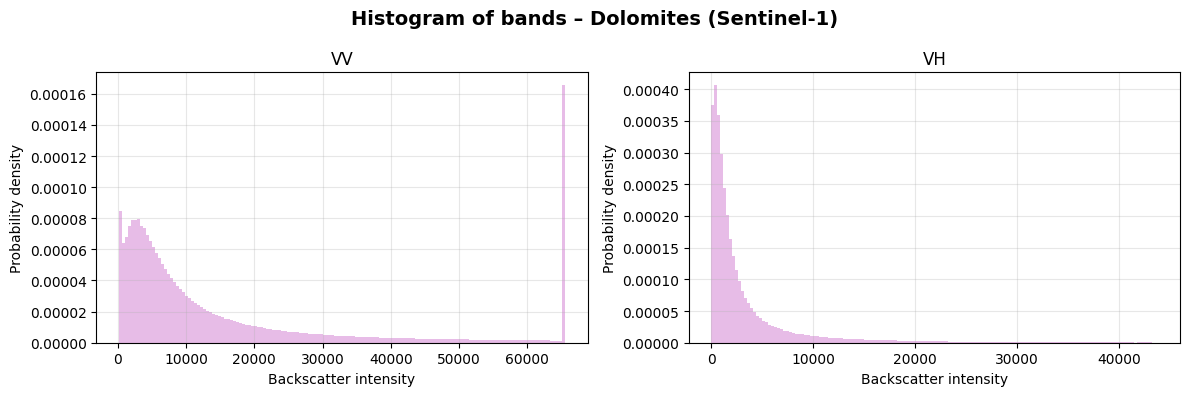

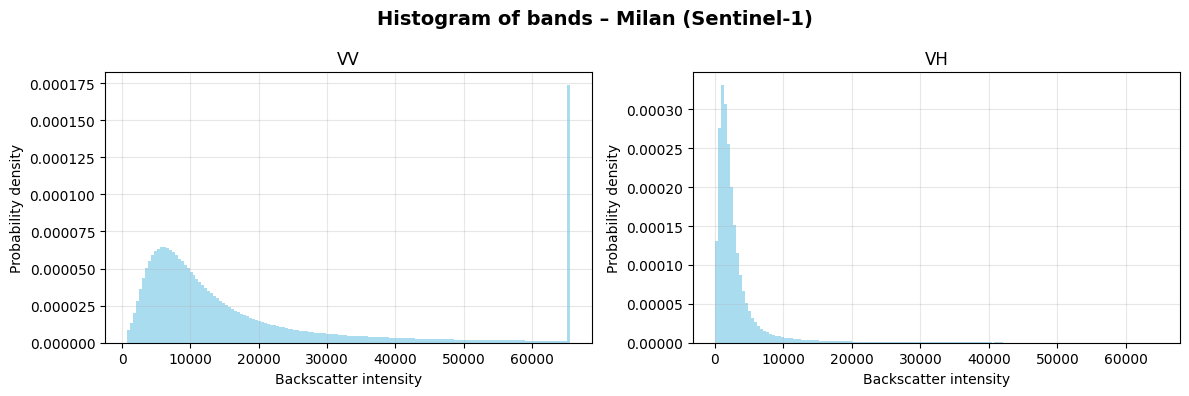

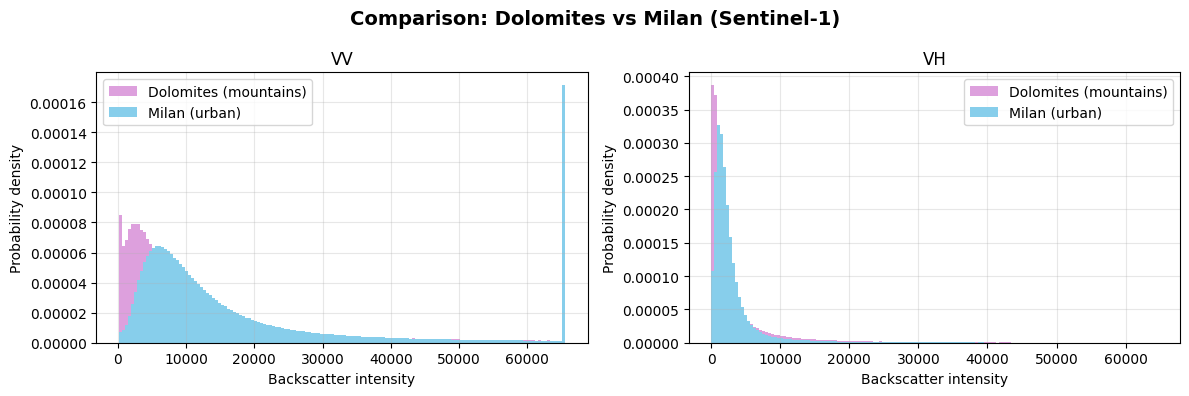

In [30]:
# Dolomites
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle("Histogram of bands – Dolomites (Sentinel-1)",
             fontsize=14,
             fontweight="bold")

for ax, band in zip(axes.flat, s1_bands):
    data = load_image("Sentinel-1", "Dolomites", band).compressed().astype(np.float64)

    vmin, vmax = np.percentile(data, [0.5, 99.5])
    bins = np.linspace(float(vmin), float(vmax), 150)

    ax.hist(data,
            color="plum",
            bins=bins,
            density=True,
            alpha=0.7)
    ax.set_title(band.upper())
    ax.set_xlabel("Backscatter intensity")
    ax.set_ylabel("Probability density")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Milan
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle("Histogram of bands – Milan (Sentinel-1)",
             fontsize=14,
             fontweight="bold")

for ax, band in zip(axes.flat, s1_bands):
    data = load_image("Sentinel-1", "Milan", band).compressed().astype(np.float64)

    vmin, vmax = np.percentile(data, [0.5, 99.5])
    bins = np.linspace(float(vmin), float(vmax), 150)

    ax.hist(data,
            color="skyblue",
            bins=bins,
            density=True,
            alpha=0.7)
    ax.set_title(band.upper())
    ax.set_xlabel("Backscatter intensity")
    ax.set_ylabel("Probability density")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# Comparison: Dolomites vs Milan
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle("Comparison: Dolomites vs Milan (Sentinel-1)",
             fontsize=14,
             fontweight="bold")

for ax, band in zip(axes.flat, s1_bands):
    dolomites = load_image("Sentinel-1", "Dolomites", band).compressed().astype(np.float64)
    milan = load_image("Sentinel-1", "Milan", band).compressed().astype(np.float64)

    vmin = min(float(np.percentile(dolomites, 0.5)), float(np.percentile(milan, 0.5)))
    vmax = max(float(np.percentile(dolomites, 99.5)), float(np.percentile(milan, 99.5)))
    bins = np.linspace(vmin, vmax, 150)

    ax.hist(dolomites,
            color="plum",
            bins=bins,
            density=True,
            linewidth=1.5,
            label="Dolomites (mountains)")
    ax.hist(milan,
            color="skyblue",
            bins=bins,
            density=True,
            linewidth=1.5,
            label="Milan (urban)")

    ax.set_title(band.upper())
    ax.set_xlabel("Backscatter intensity")
    ax.set_ylabel("Probability density")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Observations:**
All the histograms are right-skewed, it is not Gaussian distribution. The Dolomites are shifted towards low values, because steep slopes, shadow and forests scatter the signal away or are not visible to the sensor

## Stegenography

In [20]:
original = load_image("Sentinel-2", "Milan", "blue")

pixels = original.data.copy()
valid = ~np.ma.getmaskarray(original)

# random numbers generator
rng = np.random.default_rng(213)
random_bits = rng.integers(0, 4, size=valid.sum(), dtype=np.uint16)

modified = pixels.copy()

# clears the 2 LSBs (value % 4) and substitutes them with random bits
modified[valid] = pixels[valid] - (pixels[valid] % 4) + random_bits
difference = modified.astype(np.int32) - pixels.astype(np.int32)

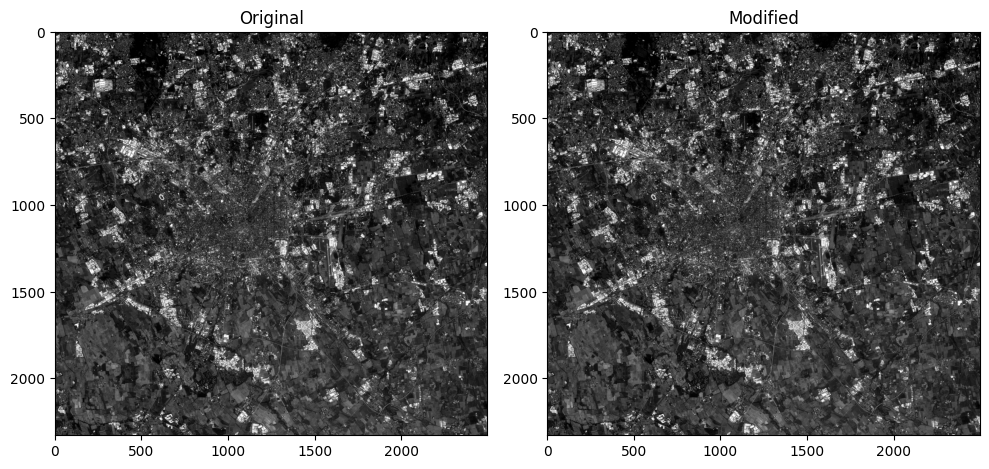

In [36]:
vmin, vmax = np.percentile(pixels[valid], [2, 98])

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(original, cmap="gray", vmin=vmin, vmax=vmax)
axes[0].set_title("Original")

axes[1].imshow(
    np.ma.array(modified, mask=~valid),
    cmap="gray",
    vmin=vmin,
    vmax=vmax
)
axes[1].set_title("Modified")

plt.tight_layout()
plt.show()

It's impossible to see the difference between the pictures, so it has to be examined. analytically

### Histogram comparison

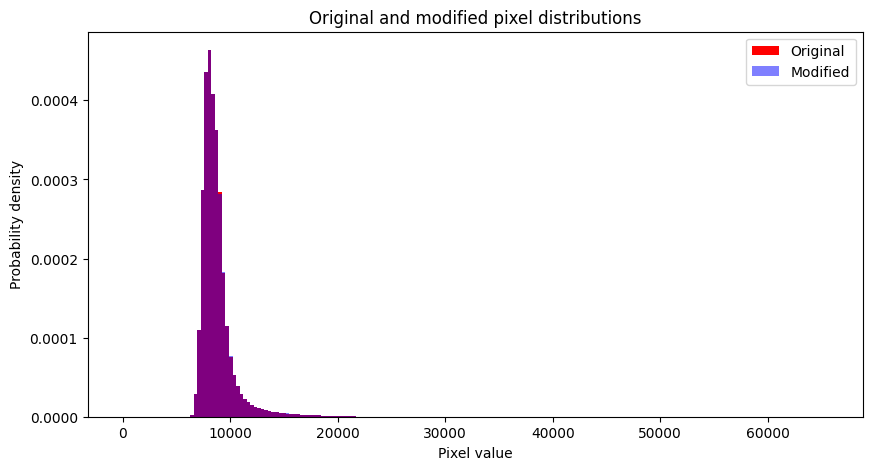

In [44]:
original_values = pixels[valid]
modified_values = modified[valid]

maximum = int(max(original_values.max(), modified_values.max()))
bins = np.linspace(0, maximum + 1, 200)

plt.figure(figsize=(10, 5))

plt.hist(original_values,
         bins=bins,
         density=True,
         color="red",
         label="Original")

plt.hist(modified_values,
         bins=bins,
         density=True,
         alpha=0.5,
         color="blue",
         label="Modified")

plt.title("Original and modified pixel distributions")
plt.xlabel("Pixel value")
plt.ylabel("Probability density")
plt.legend()
plt.show()

**Observations:**
The original and modified histograms overlap almost perfectly, because randomising the 2 LSBs only moves pixels between 4 neighbouring values.

The histogram comparison is not enough to detect the difference between these two imageries, so other methods, such as statistical tests, noise analysis are needed.